# Market tests and historical forecasting

Use the project's fixed source tables to inspect a joint-model restriction, recompute forecast scores and view all 183 historical test dates.

**Attribution:** Binance Vision-derived tables and plots retain CC BY-NC-SA 4.0. This notebook uses the original results and does not refit on the evaluation dates.

中文：读取固定源表，核对联合模型约束、预测评分与全部183个历史测试日期。

In [1]:
from pathlib import Path
import sys, os, csv
ROOT = Path.cwd()
while not (ROOT / "src/econophysics").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
def read_table(name):
    with (ROOT / "results/tables" / name).open() as f:
        return list(csv.DictReader(f))
print("Repository found. Shared implementation and frozen tables are available.")

Repository found. Shared implementation and frozen tables are available.


## 1. A necessary model restriction

The fixed action and observation interface requires

$$\Delta=\frac{\mathbb E[S_3]}{N\mathbb E[S_2]}\in[1/N,1].$$

The observed form uses return and volume moments. The table below is the original BTCUSDT 2025 H2 calculation, with seven-day date blocks.

In [2]:
market = read_table("real_market_v1/market_metrics.csv")
delta = next(r for r in market if r["source"] == "Market H2" and r["metric"] == "delta" and int(r["day_block_length"]) == 7)
print(delta)
assert float(delta["estimate"]) < 0
assert float(delta["ci_high"]) < 0

{'source': 'Market H2', 'metric': 'delta', 'estimate': '-8.18148346674896', 'ci_low': '-11.997991393062946', 'ci_high': '-4.712038681758051', 'day_block_length': '7', 'days': '184', 'interval_note': 'Pointwise circular date-block bootstrap'}


## 2. Target and chronological protocol

For a complete UTC day, $RV_d=\sum_{j=1}^{288}r_{d,j}^2$ and $z_{d+1}=\log RV_{d+1}$. Plotting $100\sqrt{RV_d}$ gives daily volatility in percent.

Training uses 337 targets in 2025. The 90 targets in 2026 Q1 select settings. A single refit uses the 427 earlier targets, then fixed coefficients predict the 183 April–September dates. Preprocessing uses fitting dates only.

The shared `daily_losses` function recomputes the score from the saved predictions.

In [3]:
from econophysics.forecasting import daily_losses
from datetime import date, timedelta
predictions = read_table("forecast_v1/test_predictions.csv")
models = sorted({r["model"] for r in predictions})
dates = sorted({r["target_date"] for r in predictions})
assert len(dates) == 183
assert dates[0] == "2026-04-01" and dates[-1] == "2026-09-30"
assert all(date.fromisoformat(r["target_date"]) - date.fromisoformat(r["origin_date"]) == timedelta(days=1) for r in predictions)
loss = {}
for model in models:
    rows = sorted([r for r in predictions if r["model"] == model], key=lambda r:r["target_date"])
    assert len(rows) == 183
    actual = np.array([float(r["actual_rv"]) for r in rows])
    forecast = np.array([float(r["log_prediction"]) for r in rows])
    recomputed = daily_losses(actual, forecast)
    np.testing.assert_allclose(recomputed["log_mse"], [float(r["log_mse"]) for r in rows], rtol=1e-11)
    loss[model] = float(np.mean(recomputed["log_mse"]))
for model, value in loss.items(): print(f"{model:18s} log-MSE {value:.6f}")

EWMA               log-MSE 0.606913
HAR                log-MSE 0.501565
HAR+Activity       log-MSE 0.499040
HAR+All            log-MSE 0.490213
HAR+Coupling       log-MSE 0.504224
HAR+Tail           log-MSE 0.497853
Persistence        log-MSE 0.712561
RBF-All            log-MSE 0.493639
RBF-HAR            log-MSE 0.511316


In [4]:
full = loss["HAR+All"]
for reference in ["Persistence", "EWMA", "HAR"]:
    print(f"Full model relative to {reference:12s}: {100*(1-full/loss[reference]):.2f}% loss reduction")
contrasts = read_table("predictive_utility_v1/contrasts.csv")
ci = next(r for r in contrasts if r["model"]=="HAR+All" and r["baseline"]=="HAR" and r["metric"]=="log_mse" and int(r["block_days"])==7)
print("Full relative to HAR, seven-day-block interval:", ci["ci_low"], ci["ci_high"])
assert float(ci["ci_low"]) < 0 < float(ci["ci_high"])

Full model relative to Persistence : 31.20% loss reduction
Full model relative to EWMA        : 19.23% loss reduction
Full model relative to HAR         : 2.26% loss reduction
Full relative to HAR, seven-day-block interval: -0.11495093866013217 4.559132186231229


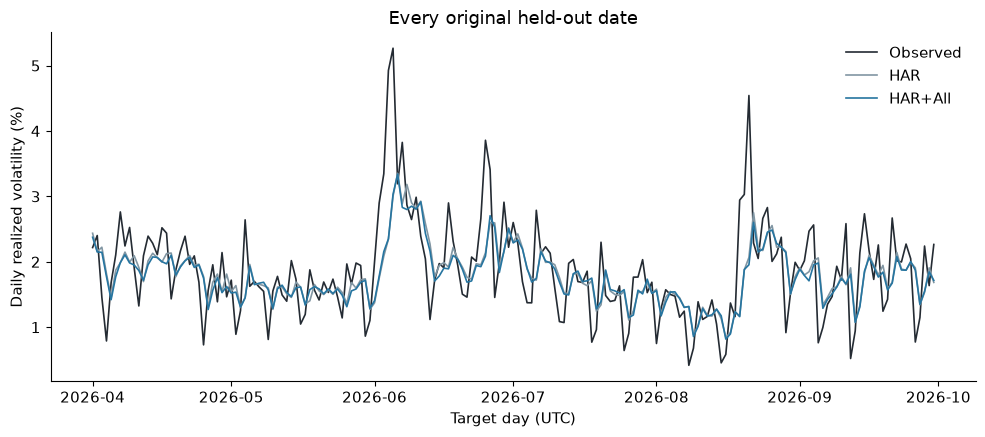

In [5]:
rows_by_model = {m:sorted([r for r in predictions if r["model"]==m], key=lambda r:r["target_date"]) for m in ["HAR","HAR+All"]}
x = np.array([np.datetime64(d) for d in dates])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x, [float(r["actual_volatility_pct"]) for r in rows_by_model["HAR"]], color="#242b33", linewidth=1.2, label="Observed")
for model, color in [("HAR", "#8196a3"), ("HAR+All", "#2675a0")]:
    ax.plot(x, [float(r["prediction_volatility_pct"]) for r in rows_by_model[model]], color=color, linewidth=1.2, label=model)
ax.set(xlabel="Target day (UTC)", ylabel="Daily realized volatility (%)", title="Every original held-out date")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## Reading the results

The complete model has historical skill relative to persistence and EWMA. The additional improvement over HAR is small and its interval crosses zero. Monthly and later-control results remain in the report.

For a full reconstruction from documented archives, run `python scripts/reproduce.py --profile forecast --destination /tmp/forecast-rerun` from the repository root.